In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Load Dataset

In [2]:
df=pd.read_csv("C:/Users/Sarthak Bhawankar/Downloads/cart_abandonment_messy_big_dataset_51000_rows (1).csv")
df.head()

,Customer_ID,Age,Gender,Device,Traffic_Source,Product_Category,Cart_Value,Discount_Percent,Session_Duration_Min,Pages_Viewed,Previous_Purchases,Returned_Customer,Payment_Method,Shipping_Cost,Abandoned
0,C115267,40,male,tablet,organic search,Sports,3210.7,10,13.33,6,7,yes,COD,79,Yes
1,C141710,32,FEMALE,Tablet,Email,Sports,3098.63,NaN,3.44,3,0,N,Wallet,149,NaN
2,C147489,58,male,desktop,Email,Fashion,2546.61,25,9.28,14,2,YES,COD,249,No
3,C114353,24,MALE,MOBILE,Email,home & kitchen,2073.99,10%,8.67,20,1,yes,NaN,149,no
4,C116391,62,MALE,NaN,NaN,Electronics,3418.23,0,6.77,22,3,yes,cod,149,yes


#### Understand 

In [3]:
df.shape

(51000, 15)

#### Check Column Name

In [4]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'Device', 'Traffic_Source',
       'Product_Category', 'Cart_Value', 'Discount_Percent',
       'Session_Duration_Min', 'Pages_Viewed', 'Previous_Purchases',
       'Returned_Customer', 'Payment_Method', 'Shipping_Cost', 'Abandoned'],
      dtype='str')

#### First and Last Record

In [5]:
df.head()

,Customer_ID,Age,Gender,Device,Traffic_Source,Product_Category,Cart_Value,Discount_Percent,Session_Duration_Min,Pages_Viewed,Previous_Purchases,Returned_Customer,Payment_Method,Shipping_Cost,Abandoned
0,C115267,40,male,tablet,organic search,Sports,3210.7,10,13.33,6,7,yes,COD,79,Yes
1,C141710,32,FEMALE,Tablet,Email,Sports,3098.63,NaN,3.44,3,0,N,Wallet,149,NaN
2,C147489,58,male,desktop,Email,Fashion,2546.61,25,9.28,14,2,YES,COD,249,No
3,C114353,24,MALE,MOBILE,Email,home & kitchen,2073.99,10%,8.67,20,1,yes,NaN,149,no
4,C116391,62,MALE,NaN,NaN,Electronics,3418.23,0,6.77,22,3,yes,cod,149,yes


In [6]:
df.tail()

,Customer_ID,Age,Gender,Device,Traffic_Source,Product_Category,Cart_Value,Discount_Percent,Session_Duration_Min,Pages_Viewed,Previous_Purchases,Returned_Customer,Payment_Method,Shipping_Cost,Abandoned
50995,C142698,18,female,mobile,Email,Fashion,2712.67,30,7.84,13,3,N,Wallet,249,NaN
50996,C136009,58,MALE,Mobile,Instagram,home & kitchen,1236.91,20,8.66,15,1,NaN,credit card,NaN,Yes
50997,C146266,29,other,NaN,NaN,electronics,$899,30,2.28,4,3,No,UPI,199,NO
50998,C123588,23,MALE,NaN,Organic Search,NaN,1812.72,NaN,1.98,20,0,NaN,cod,free,Unknown
50999,C129314,31,female,Mobile,Google Ads,Sports,3150.04,15,17.3,11,2,Unknown,Debit Card,₹99,no


#### Check Data Info

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Customer_ID           51000 non-null  str  
 1   Age                   50849 non-null  str  
 2   Gender                45287 non-null  str  
 3   Device                44514 non-null  str  
 4   Traffic_Source        46253 non-null  str  
 5   Product_Category      45809 non-null  str  
 6   Cart_Value            50889 non-null  str  
 7   Discount_Percent      41676 non-null  str  
 8   Session_Duration_Min  50920 non-null  str  
 9   Pages_Viewed          50813 non-null  str  
 10  Previous_Purchases    50894 non-null  str  
 11  Returned_Customer     45237 non-null  str  
 12  Payment_Method        46287 non-null  str  
 13  Shipping_Cost         46406 non-null  str  
 14  Abandoned             44619 non-null  str  
dtypes: str(15)
memory usage: 5.8 MB


#### Statistical info

In [8]:
df.describe()

,Customer_ID,Age,Gender,Device,Traffic_Source,Product_Category,Cart_Value,Discount_Percent,Session_Duration_Min,Pages_Viewed,Previous_Purchases,Returned_Customer,Payment_Method,Shipping_Cost,Abandoned
count,51000,50849,45287,44514,46253,45809,50889,41676,50920,50813,50894,45237,46287,46406,44619
unique,50000,52,8,7,10,9,46260,9,3230,26,10,8,10,10,7
top,C123445,59,Female,Desktop,instagram,Electronics,$899,0,999,5,6,yes,Wallet,0,No
freq,2,1135,5715,6482,4719,5181,130,4779,103,2175,6410,5751,4703,4749,6462


#### Standardize Column Names

In [9]:
df.columns = df.columns.str.strip()
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(" ","_")


In [10]:
df.columns

Index(['customer_id', 'age', 'gender', 'device', 'traffic_source',
       'product_category', 'cart_value', 'discount_percent',
       'session_duration_min', 'pages_viewed', 'previous_purchases',
       'returned_customer', 'payment_method', 'shipping_cost', 'abandoned'],
      dtype='str')

#### Check Duplicate Records

In [11]:
df.duplicated().sum()

np.int64(1000)

In [12]:
df[df.duplicated()]

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
1080,C138173,50,FEMALE,desktop,google ads,Sports,1415.18,5,8.16,15,5,NaN,credit card,NaN,no
1458,C127239,23,other,tablet,Facebook,electronics,not available,25,9.67,21,2,N,Credit Card,149 INR,NaN
2149,C146957,58,male,Desktop,instagram,Sports,1180.8,15,13.35,23,0,YES,Wallet,0,No
3989,C112466,38,Male,Tablet,Organic Search,Home & Kitchen,1266.98,10%,7.17,7,3,no,NaN,free,YES
4007,C132059,35,NaN,NaN,google ads,Sports,255.81,NaN,1.76,23,7,yes,Wallet,79,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50855,C149718,57,MALE,Tablet,google ads,electronics,2348.5,30,7.41,12,1,YES,UPI,99,Yes
50874,C143344,43,Male,desktop,NaN,fashion,890.49,25,8.7,11,0,NaN,cod,249,YES
50909,C111712,36,Female,mobile,google ads,Books,1616.63,15,7.35,18,7,YES,Wallet,NaN,Unknown
50921,C133876,18,Female,mobile,instagram,home & kitchen,1255.87,20,12.18,12,6,NaN,cod,79,NO


In [13]:
df['customer_id'].value_counts().head(10)

customer_id
C123445    2
C128170    2
C106218    2
C108719    2
C126511    2
C142295    2
C137287    2
C147768    2
C112145    2
C144347    2
Name: count, dtype: int64

In [14]:
df[df['customer_id'] == 'C137287']

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
173,C137287,58,Female,Desktop,Instagram,Home & Kitchen,1536.06,30,8.85,13,1,no,Net Banking,79,YES
33953,C137287,58,Female,Desktop,Instagram,Home & Kitchen,1536.06,30,8.85,13,1,no,Net Banking,79,YES


In [15]:
for col in df.columns:
    if df[col].nunique() <20:
        print(df[col].value_counts())
        print('-'*50)

gender
Female     5715
 male      5702
MALE       5702
Male       5678
other      5666
Other      5655
female     5611
FEMALE     5558
Name: count, dtype: int64
--------------------------------------------------
device
Desktop     6482
Tablet      6452
mobile      6399
Mobile      6374
desktop     6307
tablet      6275
MOBILE      6225
Name: count, dtype: int64
--------------------------------------------------
traffic_source
instagram         4719
Facebook          4665
Google Ads        4664
Instagram         4644
 Email            4631
organic search    4614
email             4611
google ads        4595
Direct            4584
Organic Search    4526
Name: count, dtype: int64
--------------------------------------------------
product_category
Electronics       5181
Books             5172
Sports            5148
Fashion           5115
fashion           5103
Home & Kitchen    5072
home & kitchen    5052
Beauty            5033
electronics       4933
Name: count, dtype: int64
-------------

#### Handling missing data

In [16]:
df.dropna(subset=['customer_id'], inplace = True)
df

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
0,C115267,40,male,tablet,organic search,Sports,3210.7,10,13.33,6,7,yes,COD,79,Yes
1,C141710,32,FEMALE,Tablet,Email,Sports,3098.63,NaN,3.44,3,0,N,Wallet,149,NaN
2,C147489,58,male,desktop,Email,Fashion,2546.61,25,9.28,14,2,YES,COD,249,No
3,C114353,24,MALE,MOBILE,Email,home & kitchen,2073.99,10%,8.67,20,1,yes,NaN,149,no
4,C116391,62,MALE,NaN,NaN,Electronics,3418.23,0,6.77,22,3,yes,cod,149,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50995,C142698,18,female,mobile,Email,Fashion,2712.67,30,7.84,13,3,N,Wallet,249,NaN
50996,C136009,58,MALE,Mobile,Instagram,home & kitchen,1236.91,20,8.66,15,1,NaN,credit card,NaN,Yes
50997,C146266,29,other,NaN,NaN,electronics,$899,30,2.28,4,3,No,UPI,199,NO
50998,C123588,23,MALE,NaN,Organic Search,NaN,1812.72,NaN,1.98,20,0,NaN,cod,free,Unknown


In [17]:
df.isnull().sum()

customer_id                0
age                      151
gender                  5713
device                  6486
traffic_source          4747
product_category        5191
cart_value               111
discount_percent        9324
session_duration_min      80
pages_viewed             187
previous_purchases       106
returned_customer       5763
payment_method          4713
shipping_cost           4594
abandoned               6381
dtype: int64

#### Clean Age

In [18]:
df['age'].unique()

<StringArray>
[         '40',          '32',          '58',          '24',          '62',
          '19',          '47',          '55',          '51',          '42',
          '41',          '53',          '34',          '26',          '29',
          '44',          '36',          '31',          '39',          '56',
          '59',          '63',          '46',          '35',          '48',
          '30',          '52',          '20',          '54',          '64',
          '45',          '21',          '43',          '38',          '28',
          '60',          '25',          '23',          '61',          '57',
          '22',          '18',          '49',          '50',          '27',
 'twenty five',          '-5',          '37',           '0',     'unknown',
          '33',           nan,         '150']
Length: 53, dtype: str

In [75]:
df['age'] = df["age"].astype(int)
df["age"].dtype

dtype('int64')

In [76]:
df["age"] = pd.to_numeric(df["age"],errors="coerce")

In [77]:
df.loc[(df["age"] < 18) | (df["age"] > 100),"age"]

Series([], Name: age, dtype: int64)

In [78]:
df.loc[(df["age"] < 18) | (df["age"] > 100),"age"] = np.nan

In [79]:
age_median = df["age"].median()

In [81]:
df["age"] = df["age"].fillna(age_median)
age_median

np.float64(41.0)

In [73]:
df['age'].unique()

array([40, 58, 24, 62, 51, 32, 41, 53, 26, 47, 29, 44, 36, 39, 56, 59, 63,
       35, 30, 52, 20, 54, 64, 45, 42, 21, 43, 28, 38, 46, 48, 60, 23, 61,
       57, 22, 18, 34, 25, 49, 50, 19, 27, 55, 31, 37, 33])

In [25]:
df.isnull().sum()

customer_id                0
age                        0
gender                  5713
device                  6486
traffic_source          4747
product_category        5191
cart_value               111
discount_percent        9324
session_duration_min      80
pages_viewed             187
previous_purchases       106
returned_customer       5763
payment_method          4713
shipping_cost           4594
abandoned               6381
dtype: int64

#### Clean categorial Columns

In [26]:
categorical_cols = [
    "gender",
    "device",
    "traffic_source",
    "product_category",
    "returned_customer",
    "payment_method",
    "abandoned"
]

In [27]:
for col in categorical_cols:
    df[col] = df[col].astype("string").str.strip()


#### Standardize Text

In [28]:
text_cols = [
    "gender",
    "device",
    "traffic_source",
    "product_category",
    "payment_method"
]

for col in text_cols:
    df[col] = df[col].str.title()

#### Standardize yes/no col

In [29]:
df["returned_customer"] = (df["returned_customer"].str.lower().replace({ "y": "yes","n": "no", "1": "yes", "0": "no"})
.str.title())

In [30]:
df["abandoned"] = (
    df["abandoned"]
    .str.lower()
    .replace({
        "y": "yes",
        "n": "no",
        "1": "yes",
        "0": "no"
    })
    .str.title()
)

In [31]:
df["abandoned"].unique()

<StringArray>
['Yes', <NA>, 'No', 'Unknown']
Length: 4, dtype: string

#### Clean Cart Value

In [32]:
df["cart_value"] = (
    df["cart_value"]
    .astype("string")
    .str.replace("₹", "", regex=False)
    .str.replace("$", "", regex=False)
    .str.replace("INR", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

In [33]:
df["cart_value"] = pd.to_numeric(
    df["cart_value"],
    errors="coerce"
)

#### Clean discount percent

In [34]:
df["discount_percent"] = (
    df["discount_percent"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.strip()
)

In [35]:
df["discount_percent"] = pd.to_numeric(
    df["discount_percent"],
    errors="coerce"
)

In [36]:
df

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
0,C115267,40.0,Male,Tablet,Organic Search,Sports,3210.7,10,13.33,6,7,Yes,Cod,79,Yes
1,C141710,32.0,Female,Tablet,Email,Sports,3098.63,<NA>,3.44,3,0,No,Wallet,149,<NA>
2,C147489,58.0,Male,Desktop,Email,Fashion,2546.61,25,9.28,14,2,Yes,Cod,249,No
3,C114353,24.0,Male,Mobile,Email,Home & Kitchen,2073.99,10,8.67,20,1,Yes,<NA>,149,No
4,C116391,62.0,Male,<NA>,<NA>,Electronics,3418.23,0,6.77,22,3,Yes,Cod,149,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50995,C142698,18.0,Female,Mobile,Email,Fashion,2712.67,30,7.84,13,3,No,Wallet,249,<NA>
50996,C136009,58.0,Male,Mobile,Instagram,Home & Kitchen,1236.91,20,8.66,15,1,<NA>,Credit Card,NaN,Yes
50997,C146266,29.0,Other,<NA>,<NA>,Electronics,899.0,30,2.28,4,3,No,Upi,199,No
50998,C123588,23.0,Male,<NA>,Organic Search,<NA>,1812.72,<NA>,1.98,20,0,<NA>,Cod,free,Unknown


#### Clean session duration

In [37]:
df['session_duration_min'].unique()

<StringArray>
['13.33',  '3.44',  '9.28',  '8.67',  '6.77',  '2.56', '12.07', '20.02',
  '4.77', '11.03',
 ...
 '27.91', '28.14', '24.33', '25.64', '37.01',  '0.04',  '26.8', '26.31',
 '34.57', '37.15']
Length: 3231, dtype: str

In [38]:
df["session_duration_min"] = pd.to_numeric(
    df["session_duration_min"],
    errors="coerce"
)

In [39]:
df.loc[
    df["session_duration_min"] < 0,
    "session_duration_min"
] = np.nan ####Remove immposible negative value

#### Clean pages viewed

In [40]:
df['pages_viewed'].unique()

<StringArray>
[       '6',        '3',       '14',       '20',       '22',        '1',
       '15',       '21',        '9',       '12',       '13',       '18',
       '16',       '17',        '5',       '11',       '23',       '10',
        '2',       '19',        '4',        '8', '12 pages',       '24',
        nan,        '7',       '-1']
Length: 27, dtype: str

In [41]:
df["pages_viewed"] = pd.to_numeric(
    df["pages_viewed"],
    errors="coerce"
)

In [42]:
df.loc[
    df["pages_viewed"] <= 0,
    "pages_viewed"
] == np.nan

734      False
870      False
1025     False
1167     False
1671     False
         ...  
44485    False
44870    False
46151    False
46623    False
48100    False
Name: pages_viewed, Length: 77, dtype: bool

#### Clean Previous Purchase

In [43]:
df['previous_purchases'].unique()

<StringArray>
['7', '0', '2', '1', '3', '5', '6', '4', nan, '-2', 'none']
Length: 11, dtype: str

In [44]:
df['previous_purchases'] = pd.to_numeric(
    df['previous_purchases'],errors='coerce')

In [45]:
df.loc[df['previous_purchases']<0,'previous_purchases'] = np.nan

#### Clean Shipping Cost

In [46]:
df['shipping_cost'].unique()

<StringArray>
['79', '149', '249', nan, '199', '99', '0', '149 INR', '49', '₹99', 'free']
Length: 11, dtype: str

In [47]:

df['shipping_cost'] = (df['shipping_cost']
    .astype('string')
    .str.replace('₹', '', regex=False)
    .str.replace('INR', '',regex=False)
    .str.strip())

In [48]:
df['shipping_cost']=df['shipping_cost'].replace('free','0')
df

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
0,C115267,40.0,Male,Tablet,Organic Search,Sports,3210.7,10,13.33,6.0,7.0,Yes,Cod,79,Yes
1,C141710,32.0,Female,Tablet,Email,Sports,3098.63,<NA>,3.44,3.0,0.0,No,Wallet,149,<NA>
2,C147489,58.0,Male,Desktop,Email,Fashion,2546.61,25,9.28,14.0,2.0,Yes,Cod,249,No
3,C114353,24.0,Male,Mobile,Email,Home & Kitchen,2073.99,10,8.67,20.0,1.0,Yes,<NA>,149,No
4,C116391,62.0,Male,<NA>,<NA>,Electronics,3418.23,0,6.77,22.0,3.0,Yes,Cod,149,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50995,C142698,18.0,Female,Mobile,Email,Fashion,2712.67,30,7.84,13.0,3.0,No,Wallet,249,<NA>
50996,C136009,58.0,Male,Mobile,Instagram,Home & Kitchen,1236.91,20,8.66,15.0,1.0,<NA>,Credit Card,<NA>,Yes
50997,C146266,29.0,Other,<NA>,<NA>,Electronics,899.0,30,2.28,4.0,3.0,No,Upi,199,No
50998,C123588,23.0,Male,<NA>,Organic Search,<NA>,1812.72,<NA>,1.98,20.0,0.0,<NA>,Cod,0,Unknown


In [49]:
df['shipping_cost']= pd.to_numeric(df['shipping_cost'],errors='coerce')
df['shipping_cost']=df['shipping_cost'].astype("Int64")

In [50]:
df['shipping_cost'].isna().sum()

np.int64(4594)

#### Check Numeric col

In [51]:
numeric_cols= [
    'age','cart_value','discount_percent','session_duration_min','pages_viewed','previous_purchases','shipping_cost']
df[numeric_cols].dtypes

age                     float64
cart_value              Float64
discount_percent          Int64
session_duration_min    float64
pages_viewed            float64
previous_purchases      float64
shipping_cost             Int64
dtype: object

#### Fill Numerical Missing Values

In [52]:
numerical_cols = [
    'cart_value','cart_value','discount_percent','session_duration_min','pages_viewed','previous_purchases','shipping_cost']
for col in numeric_cols:
    df[col] = df[col].fillna(
        df[col].median())

#### why median=because e-commerce numeric data can contain extreme values

#### Fill categorical Missing Values

In [53]:
categorical_cols=[
    'gender','device','traffic_source','product_category','returned_customer','payment_method']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [54]:
df

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
0,C115267,40.0,Male,Tablet,Organic Search,Sports,3210.7,10,13.33,6.0,7.0,Yes,Cod,79,Yes
1,C141710,32.0,Female,Tablet,Email,Sports,3098.63,15,3.44,3.0,0.0,No,Wallet,149,<NA>
2,C147489,58.0,Male,Desktop,Email,Fashion,2546.61,25,9.28,14.0,2.0,Yes,Cod,249,No
3,C114353,24.0,Male,Mobile,Email,Home & Kitchen,2073.99,10,8.67,20.0,1.0,Yes,Cod,149,No
4,C116391,62.0,Male,Mobile,Instagram,Electronics,3418.23,0,6.77,22.0,3.0,Yes,Cod,149,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50995,C142698,18.0,Female,Mobile,Email,Fashion,2712.67,30,7.84,13.0,3.0,No,Wallet,249,<NA>
50996,C136009,58.0,Male,Mobile,Instagram,Home & Kitchen,1236.91,20,8.66,15.0,1.0,Yes,Credit Card,99,Yes
50997,C146266,29.0,Other,Mobile,Instagram,Electronics,899.0,30,2.28,4.0,3.0,No,Upi,199,No
50998,C123588,23.0,Male,Mobile,Organic Search,Fashion,1812.72,15,1.98,20.0,0.0,Yes,Cod,0,Unknown


#### Handle Abandoned

In [55]:
df['abandoned'].unique()

<StringArray>
['Yes', <NA>, 'No', 'Unknown']
Length: 4, dtype: string

In [56]:
df['abandoned'].value_counts(dropna=False)

abandoned
No         19096
Yes        19076
Unknown     6447
<NA>        6381
Name: count, dtype: Int64

In [57]:
df=df[df['abandoned'].isin(['Yes','No'])]

In [58]:
df

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
0,C115267,40.0,Male,Tablet,Organic Search,Sports,3210.7,10,13.33,6.0,7.0,Yes,Cod,79,Yes
2,C147489,58.0,Male,Desktop,Email,Fashion,2546.61,25,9.28,14.0,2.0,Yes,Cod,249,No
3,C114353,24.0,Male,Mobile,Email,Home & Kitchen,2073.99,10,8.67,20.0,1.0,Yes,Cod,149,No
4,C116391,62.0,Male,Mobile,Instagram,Electronics,3418.23,0,6.77,22.0,3.0,Yes,Cod,149,Yes
5,C107506,62.0,Male,Mobile,Instagram,Fashion,1311.15,20,2.56,1.0,5.0,Yes,Debit Card,149,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50993,C121573,46.0,Female,Mobile,Direct,Fashion,1214.15,20,8.00,22.0,7.0,Unknown,Debit Card,0,Yes
50994,C134537,25.0,Male,Mobile,Organic Search,Electronics,418.52,30,11.85,8.0,6.0,Unknown,Upi,249,Yes
50996,C136009,58.0,Male,Mobile,Instagram,Home & Kitchen,1236.91,20,8.66,15.0,1.0,Yes,Credit Card,99,Yes
50997,C146266,29.0,Other,Mobile,Instagram,Electronics,899.0,30,2.28,4.0,3.0,No,Upi,199,No


#### Final missing value check

In [59]:
df.isnull().sum()

customer_id             0
age                     0
gender                  0
device                  0
traffic_source          0
product_category        0
cart_value              0
discount_percent        0
session_duration_min    0
pages_viewed            0
previous_purchases      0
returned_customer       0
payment_method          0
shipping_cost           0
abandoned               0
dtype: int64

#### Final Data Type check

In [74]:
df.info()

<class 'pandas.DataFrame'>
Index: 38172 entries, 0 to 50999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           38172 non-null  str    
 1   age                   38172 non-null  int64  
 2   gender                38172 non-null  string 
 3   device                38172 non-null  string 
 4   traffic_source        38172 non-null  string 
 5   product_category      38172 non-null  string 
 6   cart_value            38172 non-null  Float64
 7   discount_percent      38172 non-null  Int64  
 8   session_duration_min  38172 non-null  float64
 9   pages_viewed          38172 non-null  float64
 10  previous_purchases    38172 non-null  float64
 11  returned_customer     38172 non-null  string 
 12  payment_method        38172 non-null  string 
 13  shipping_cost         38172 non-null  Int64  
 14  abandoned             38172 non-null  string 
dtypes: Float64(1), Int64(2), float64(3)

In [61]:
df.describe()

,age,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,shipping_cost
count,38172.000000,38172.0,38172.0,38172.000000,38172.000000,38172.000000,38172.0
mean,41.121660,2211.651511,14.546526,11.620986,12.492927,3.511658,105.990779
std,13.478654,1607.964895,8.110264,45.666832,6.939151,2.285266,73.389018
min,18.000000,136.59,0.0,0.020000,-1.000000,0.000000,0.0
25%,30.000000,1158.4275,10.0,5.060000,7.000000,2.000000,49.0
50%,41.000000,1788.725,15.0,8.310000,12.000000,4.000000,99.0
75%,53.000000,2773.785,20.0,12.680000,18.000000,6.000000,149.0
max,64.000000,29964.75,30.0,999.000000,24.000000,7.000000,249.0


In [62]:
df.duplicated

<bound method DataFrame.duplicated of       customer_id   age  gender   device  traffic_source product_category  \
0         C115267  40.0    Male   Tablet  Organic Search           Sports   
2         C147489  58.0    Male  Desktop           Email          Fashion   
3         C114353  24.0    Male   Mobile           Email   Home & Kitchen   
4         C116391  62.0    Male   Mobile       Instagram      Electronics   
5         C107506  62.0    Male   Mobile       Instagram          Fashion   
...           ...   ...     ...      ...             ...              ...   
50993     C121573  46.0  Female   Mobile          Direct          Fashion   
50994     C134537  25.0    Male   Mobile  Organic Search      Electronics   
50996     C136009  58.0    Male   Mobile       Instagram   Home & Kitchen   
50997     C146266  29.0   Other   Mobile       Instagram      Electronics   
50999     C129314  31.0  Female   Mobile      Google Ads           Sports   

       cart_value  discount_percent  

#### Save clean data

In [63]:
df.to_csv("cart_abandonment_cleaned.csv",index=False)

In [64]:
df

,customer_id,age,gender,device,traffic_source,product_category,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,returned_customer,payment_method,shipping_cost,abandoned
0,C115267,40.0,Male,Tablet,Organic Search,Sports,3210.7,10,13.33,6.0,7.0,Yes,Cod,79,Yes
2,C147489,58.0,Male,Desktop,Email,Fashion,2546.61,25,9.28,14.0,2.0,Yes,Cod,249,No
3,C114353,24.0,Male,Mobile,Email,Home & Kitchen,2073.99,10,8.67,20.0,1.0,Yes,Cod,149,No
4,C116391,62.0,Male,Mobile,Instagram,Electronics,3418.23,0,6.77,22.0,3.0,Yes,Cod,149,Yes
5,C107506,62.0,Male,Mobile,Instagram,Fashion,1311.15,20,2.56,1.0,5.0,Yes,Debit Card,149,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50993,C121573,46.0,Female,Mobile,Direct,Fashion,1214.15,20,8.00,22.0,7.0,Unknown,Debit Card,0,Yes
50994,C134537,25.0,Male,Mobile,Organic Search,Electronics,418.52,30,11.85,8.0,6.0,Unknown,Upi,249,Yes
50996,C136009,58.0,Male,Mobile,Instagram,Home & Kitchen,1236.91,20,8.66,15.0,1.0,Yes,Credit Card,99,Yes
50997,C146266,29.0,Other,Mobile,Instagram,Electronics,899.0,30,2.28,4.0,3.0,No,Upi,199,No


In [65]:
df.shape

(38172, 15)

In [85]:
df.nunique()

customer_id             37415
age                        47
gender                      3
device                      3
traffic_source              6
product_category            6
cart_value              35109
discount_percent            7
session_duration_min     3061
pages_viewed               25
previous_purchases          8
returned_customer           3
payment_method              6
shipping_cost               7
abandoned                   2
dtype: int64

In [86]:
df["abandoned"].value_counts()

abandoned
No     19096
Yes    19076
Name: count, dtype: Int64

# EDA process

#### Pie chart

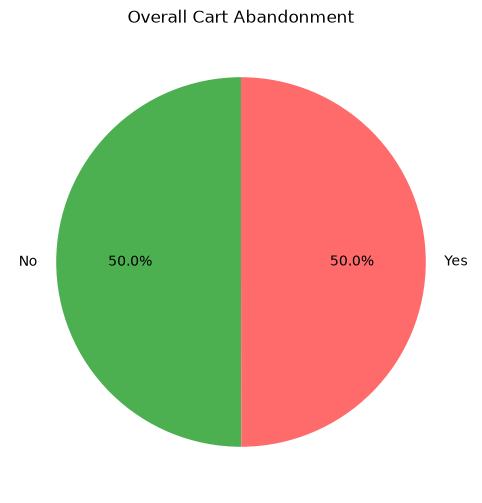

In [87]:
abandonment_counts = df["abandoned"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    abandonment_counts.values,
    labels=abandonment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4CAF50", "#FF6B6B"]
)

plt.title("Overall Cart Abandonment")
plt.show()

### Overall Abandonment Bar Chart

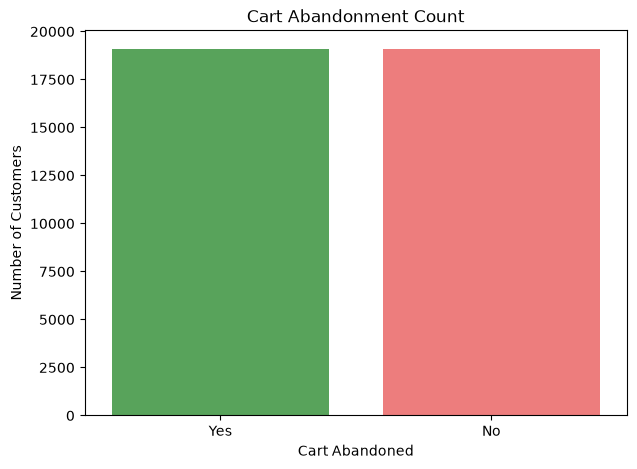

In [98]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="abandoned",
    hue="abandoned",
    palette=["#4CAF50", "#FF6B6B"],
    legend=False
)

plt.title("Cart Abandonment Count")
plt.xlabel("Cart Abandoned")
plt.ylabel("Number of Customers")
plt.show()

#### By device

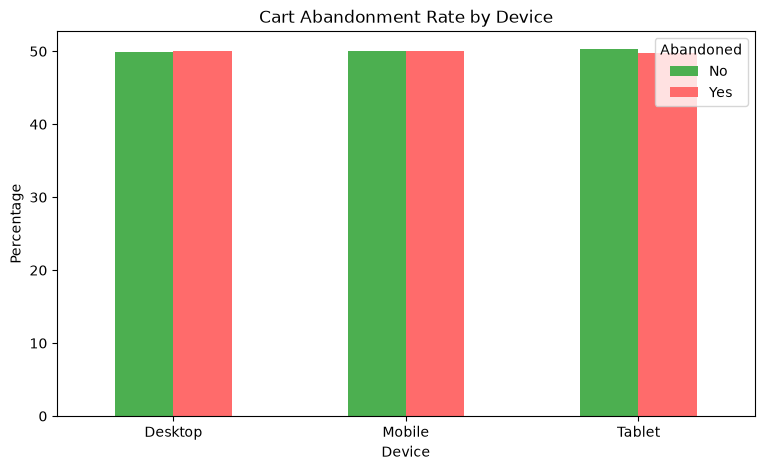

In [90]:
device_abandonment = (
    pd.crosstab(
        df["device"],
        df["abandoned"],
        normalize="index"
    ) * 100
)

device_abandonment
device_abandonment.plot(
    kind="bar",
    figsize=(9,5),
    color=["#4CAF50", "#FF6B6B"]
)

plt.title("Cart Abandonment Rate by Device")
plt.xlabel("Device")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Abandoned")
plt.show()

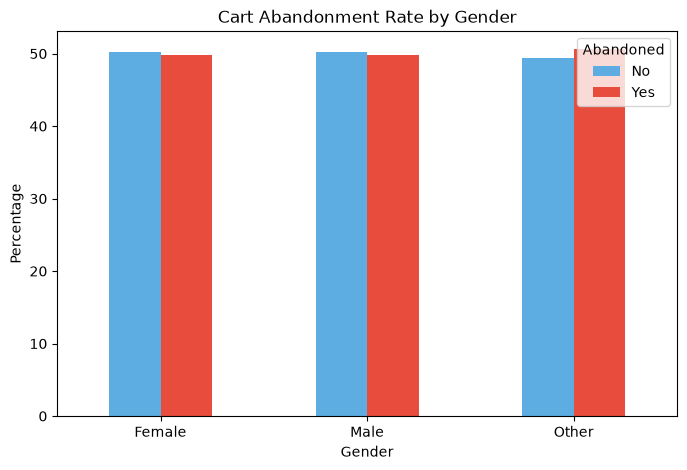

In [91]:
gender_abandonment = (
    pd.crosstab(
        df["gender"],
        df["abandoned"],
        normalize="index"
    ) * 100
)

gender_abandonment.plot(
    kind="bar",
    figsize=(8,5),
    color=["#5DADE2", "#E74C3C"]
)

plt.title("Cart Abandonment Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Abandoned")
plt.show()

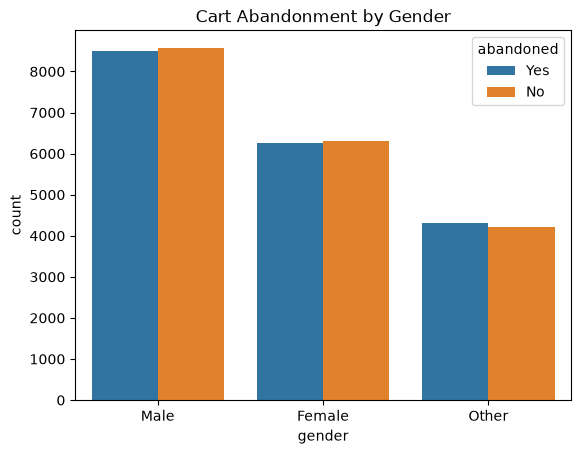

In [99]:
pd.crosstab(
    df["gender"],
    df["abandoned"],
    normalize="index"
) * 100
sns.countplot(
    data=df,
    x="gender",
    hue="abandoned"
)

plt.title("Cart Abandonment by Gender")
plt.show()

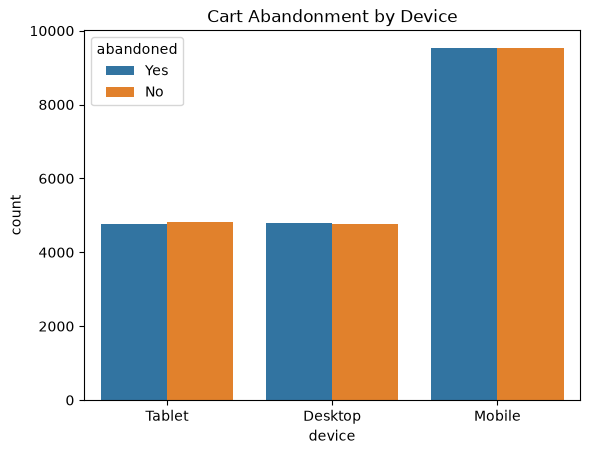

In [96]:
pd.crosstab(
    df["device"],
    df["abandoned"],
    normalize="index"
) * 100
sns.countplot(
    data=df,
    x="device",
    hue="abandoned"
)

plt.title("Cart Abandonment by Device")
plt.show()

#### Product category comparison

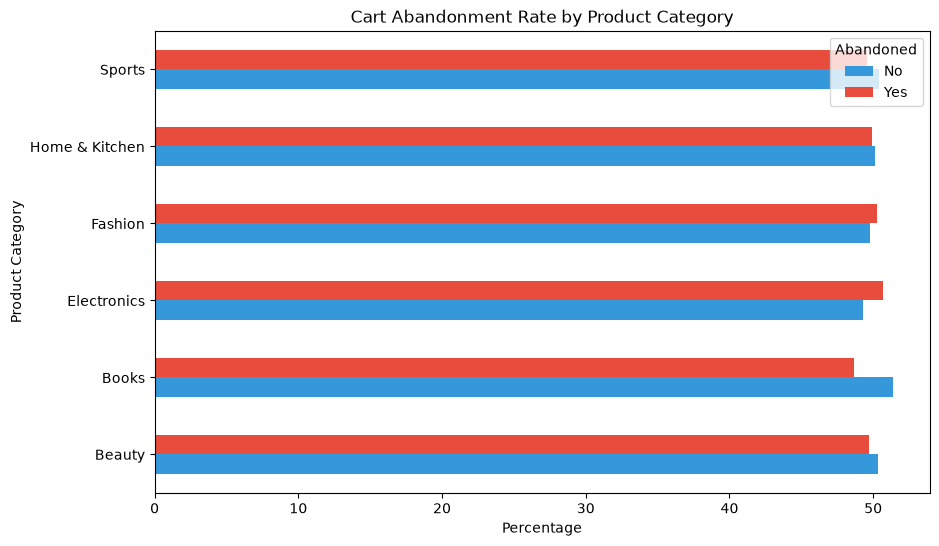

In [100]:
category_abandonment = (
    pd.crosstab(
        df["product_category"],
        df["abandoned"],
        normalize="index"
    ) * 100
)
category_abandonment.plot(
    kind="barh",
    figsize=(10,6),
    color=["#3498DB", "#E74C3C"]
)

plt.title("Cart Abandonment Rate by Product Category")
plt.xlabel("Percentage")
plt.ylabel("Product Category")
plt.legend(title="Abandoned")
plt.show()

#### Traffic source

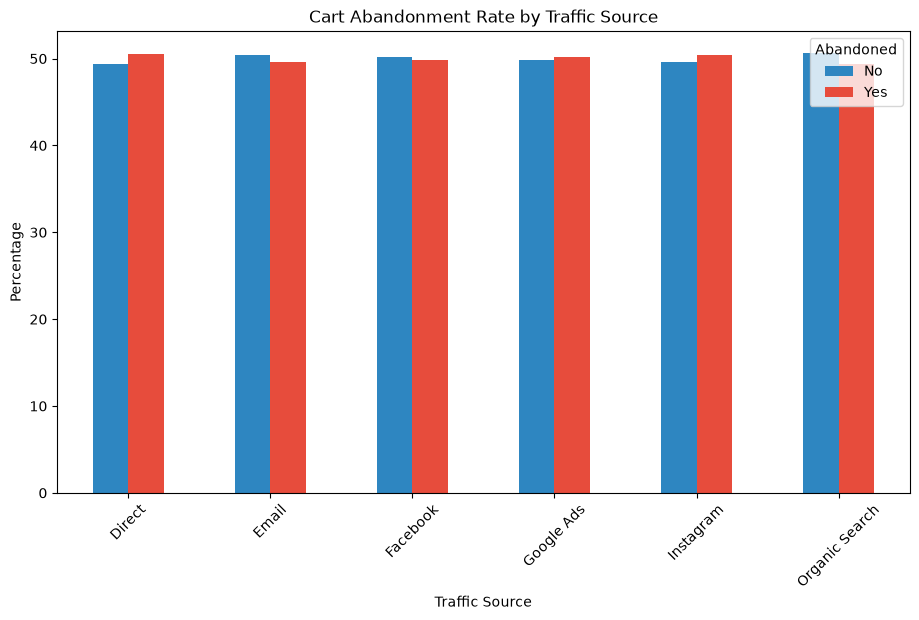

In [101]:
traffic_abandonment = (
    pd.crosstab(
        df["traffic_source"],
        df["abandoned"],
        normalize="index"
    ) * 100
)

traffic_abandonment.plot(
    kind="bar",
    figsize=(11,6),
    color=["#2E86C1", "#E74C3C"]
)

plt.title("Cart Abandonment Rate by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(title="Abandoned")
plt.show()

#### Payment method

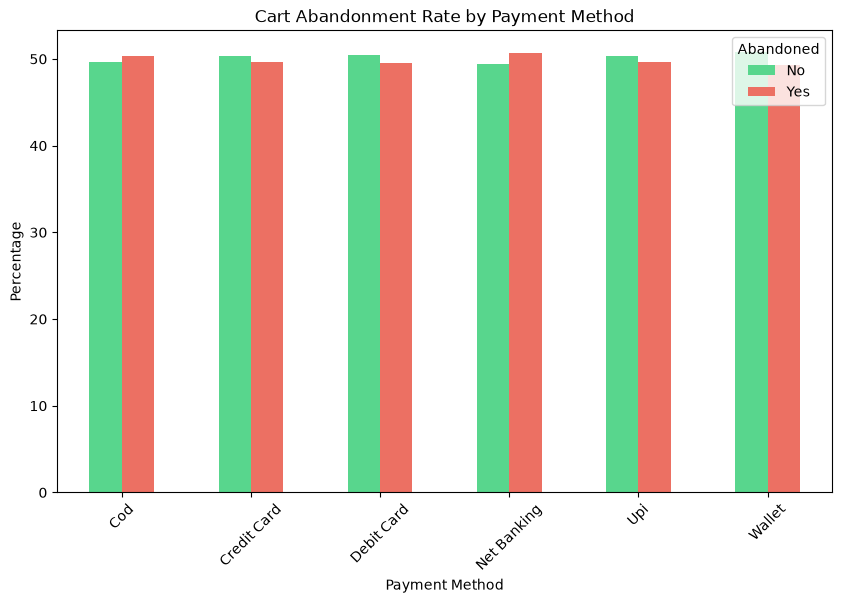

In [102]:
payment_abandonment = (
    pd.crosstab(
        df["payment_method"],
        df["abandoned"],
        normalize="index"
    ) * 100
)

payment_abandonment.plot(
    kind="bar",
    figsize=(10,6),
    color=["#58D68D", "#EC7063"]
)

plt.title("Cart Abandonment Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage")
plt.xticks(rotation=45)
plt.legend(title="Abandoned")
plt.show()

#### Returned Customer

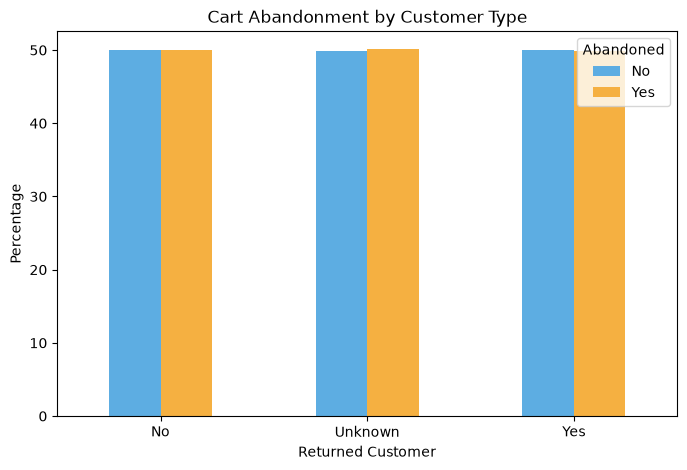

In [103]:
returned_abandonment = (
    pd.crosstab(
        df["returned_customer"],
        df["abandoned"],
        normalize="index"
    ) * 100
)

returned_abandonment.plot(
    kind="bar",
    figsize=(8,5),
    color=["#5DADE2", "#F5B041"]
)

plt.title("Cart Abandonment by Customer Type")
plt.xlabel("Returned Customer")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Abandoned")
plt.show()

#### Cart value vs Abandonment

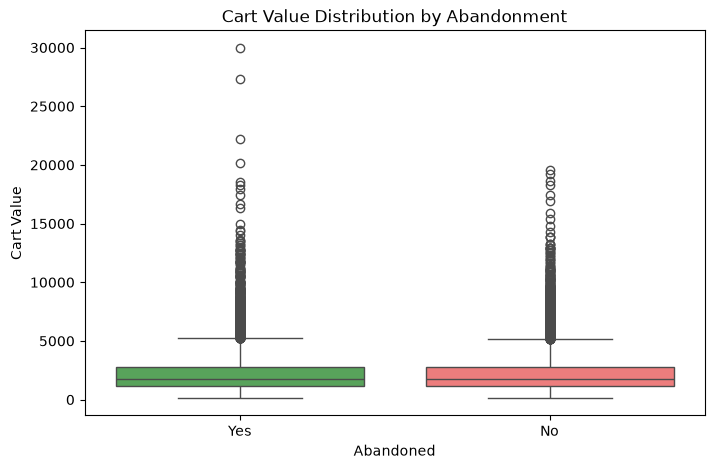

In [104]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="abandoned",
    y="cart_value",
    hue="abandoned",
    palette=["#4CAF50", "#FF6B6B"],
    legend=False
)

plt.title("Cart Value Distribution by Abandonment")
plt.xlabel("Abandoned")
plt.ylabel("Cart Value")
plt.show()

#### Discount vs Abandonment

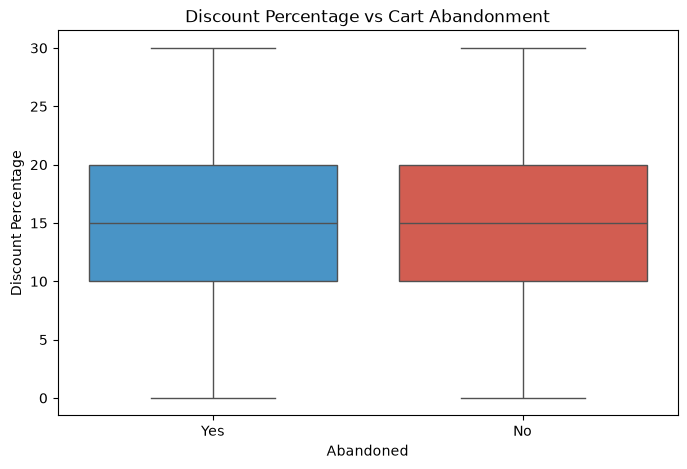

In [105]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="abandoned",
    y="discount_percent",
    hue="abandoned",
    palette=["#3498DB", "#E74C3C"],
    legend=False
)

plt.title("Discount Percentage vs Cart Abandonment")
plt.xlabel("Abandoned")
plt.ylabel("Discount Percentage")
plt.show()

#### Shipping cost vs Aband

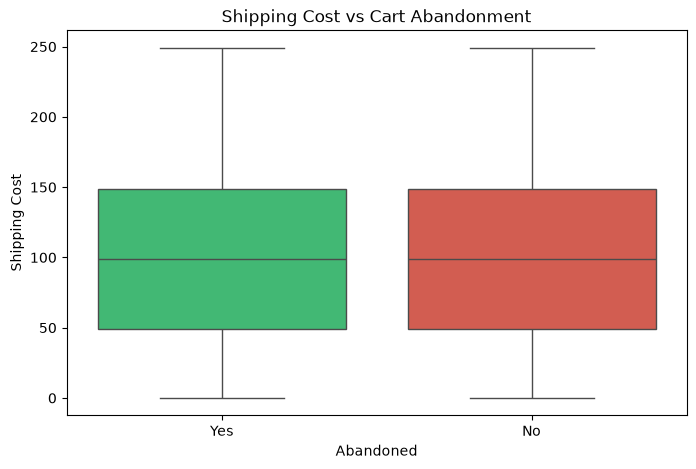

In [106]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="abandoned",
    y="shipping_cost",
    hue="abandoned",
    palette=["#2ECC71", "#E74C3C"],
    legend=False
)

plt.title("Shipping Cost vs Cart Abandonment")
plt.xlabel("Abandoned")
plt.ylabel("Shipping Cost")
plt.show()

#### Session Duration vs Abandonment

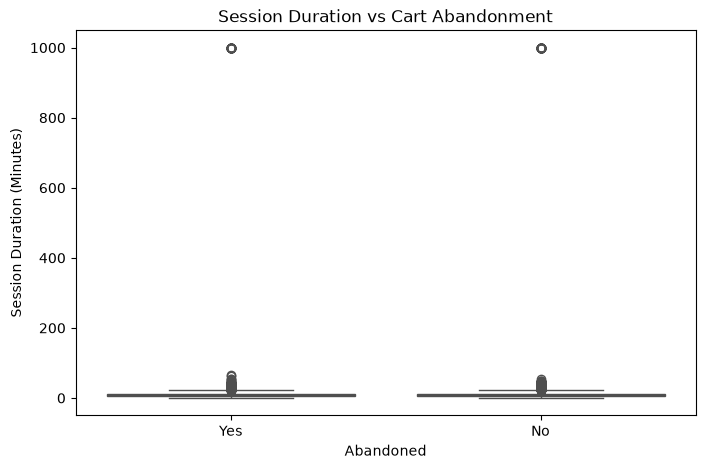

In [107]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="abandoned",
    y="session_duration_min",
    hue="abandoned",
    palette=["#3498DB", "#E67E22"],
    legend=False
)

plt.title("Session Duration vs Cart Abandonment")
plt.xlabel("Abandoned")
plt.ylabel("Session Duration (Minutes)")
plt.show()

#### Pages Viewed vs Abandonment

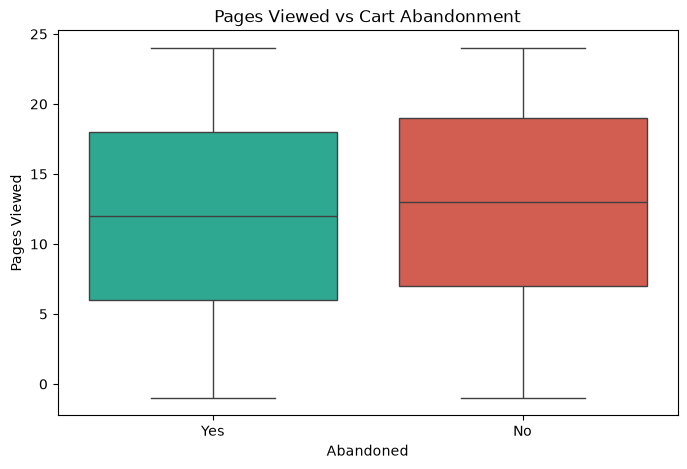

In [108]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="abandoned",
    y="pages_viewed",
    hue="abandoned",
    palette=["#1ABC9C", "#E74C3C"],
    legend=False
)

plt.title("Pages Viewed vs Cart Abandonment")
plt.xlabel("Abandoned")
plt.ylabel("Pages Viewed")
plt.show()

#### Previous Purchases vs Abandonment

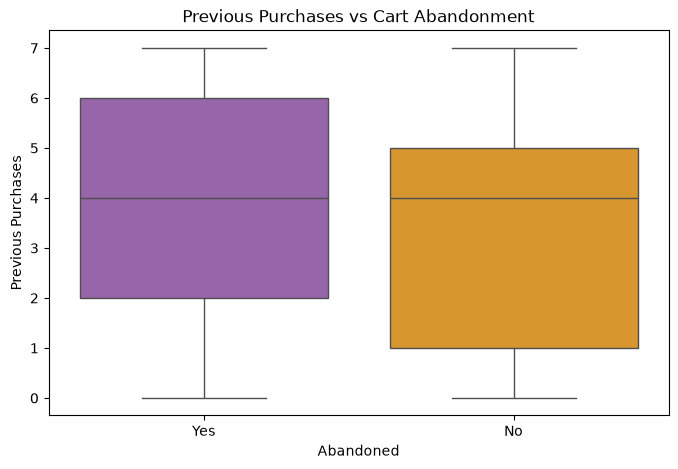

In [109]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="abandoned",
    y="previous_purchases",
    hue="abandoned",
    palette=["#9B59B6", "#F39C12"],
    legend=False
)

plt.title("Previous Purchases vs Cart Abandonment")
plt.xlabel("Abandoned")
plt.ylabel("Previous Purchases")
plt.show()

#### SCATTER PLOT

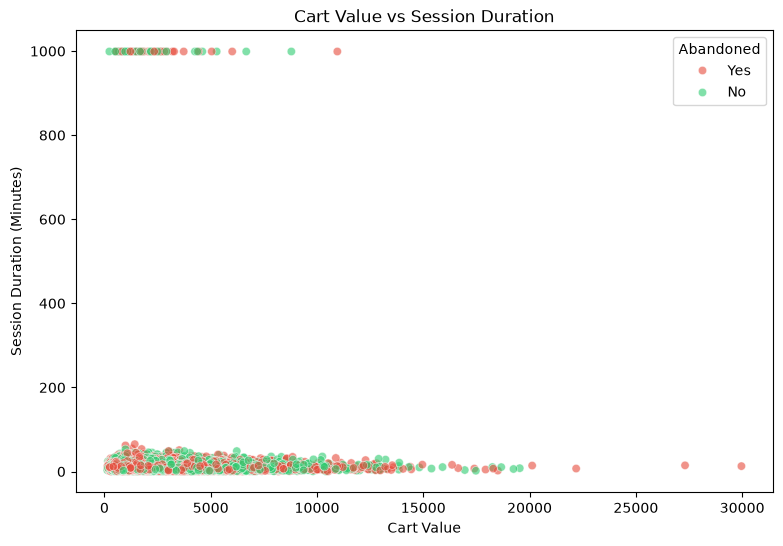

In [110]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="cart_value",
    y="session_duration_min",
    hue="abandoned",
    palette={
        "Yes": "#E74C3C",
        "No": "#2ECC71"
    },
    alpha=0.6
)

plt.title("Cart Value vs Session Duration")
plt.xlabel("Cart Value")
plt.ylabel("Session Duration (Minutes)")
plt.legend(title="Abandoned")
plt.show()

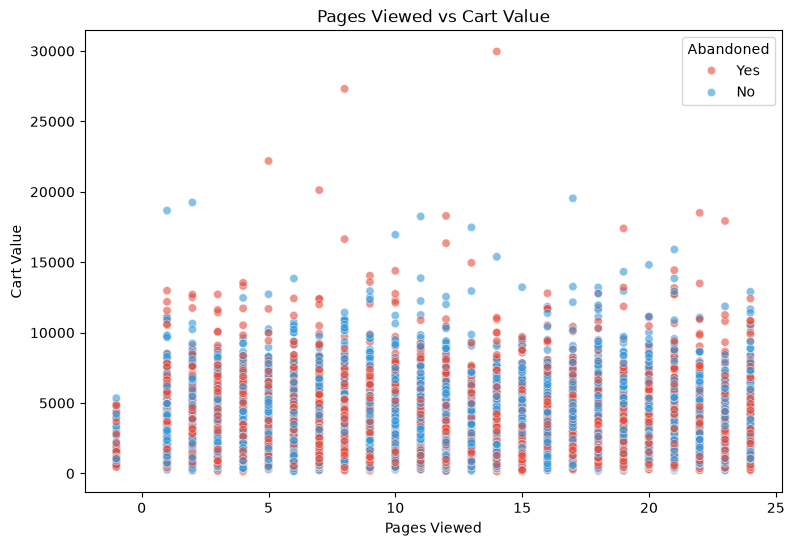

In [111]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=df,
    x="pages_viewed",
    y="cart_value",
    hue="abandoned",
    palette={
        "Yes": "#E74C3C",
        "No": "#3498DB"
    },
    alpha=0.6
)

plt.title("Pages Viewed vs Cart Value")
plt.xlabel("Pages Viewed")
plt.ylabel("Cart Value")
plt.legend(title="Abandoned")
plt.show()

#### AGE GROUP ANALYSIS

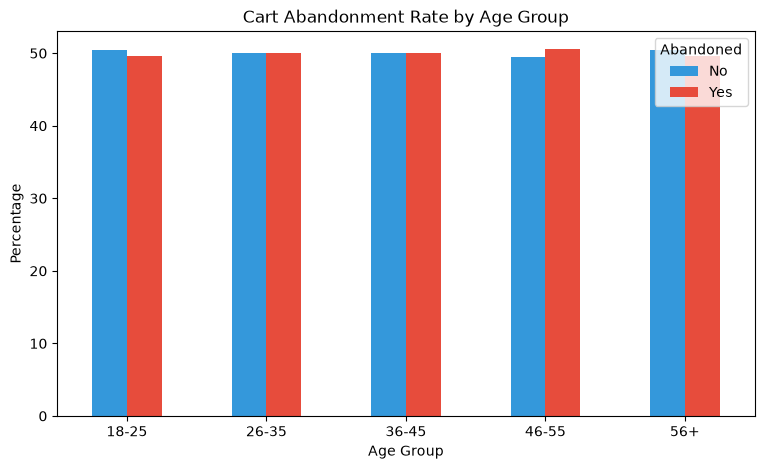

In [114]:
bins = [17, 25, 35, 45, 55, 100]

labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels
)
age_abandonment = (
    pd.crosstab(
        df["age_group"],
        df["abandoned"],
        normalize="index"
    ) * 100
)
age_abandonment.plot(
    kind="bar",
    figsize=(9,5),
    color=["#3498DB", "#E74C3C"]
)

plt.title("Cart Abandonment Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Abandoned")
plt.show()


#### Heatmap

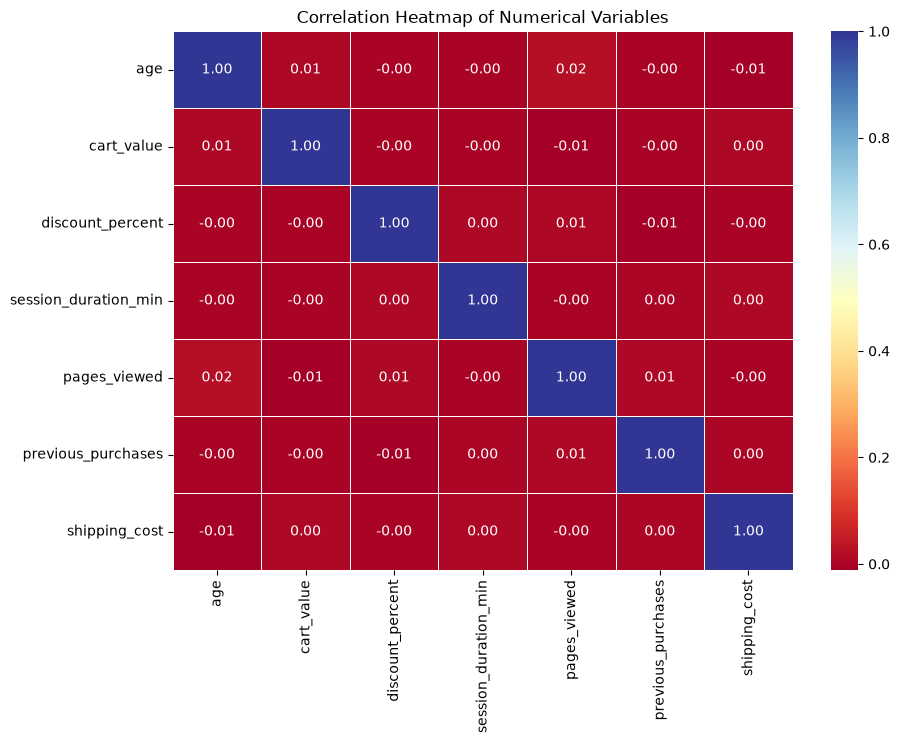

In [116]:
numeric_cols = [
    "age",
    "cart_value",
    "discount_percent",
    "session_duration_min",
    "pages_viewed",
    "previous_purchases",
    "shipping_cost"
]
correlation = df[numeric_cols].corr()
plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="RdYlBu",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

#### Abandonment Rate by Cart Value Group

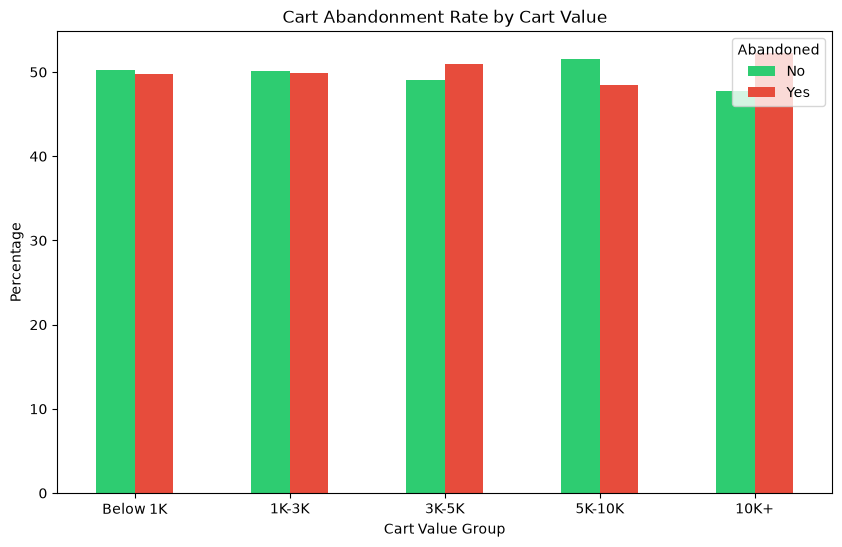

In [117]:
bins = [
    0,
    1000,
    3000,
    5000,
    10000,
    np.inf
]

labels = [
    "Below 1K",
    "1K-3K",
    "3K-5K",
    "5K-10K",
    "10K+"
]

df["cart_value_group"] = pd.cut(
    df["cart_value"],
    bins=bins,
    labels=labels
)
cart_group_analysis = (
    pd.crosstab(
        df["cart_value_group"],
        df["abandoned"],
        normalize="index"
    ) * 100
)
cart_group_analysis.plot(
    kind="bar",
    figsize=(10,6),
    color=["#2ECC71", "#E74C3C"]
)

plt.title("Cart Abandonment Rate by Cart Value")
plt.xlabel("Cart Value Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Abandoned")
plt.show()

#### Stacked Bar Chart

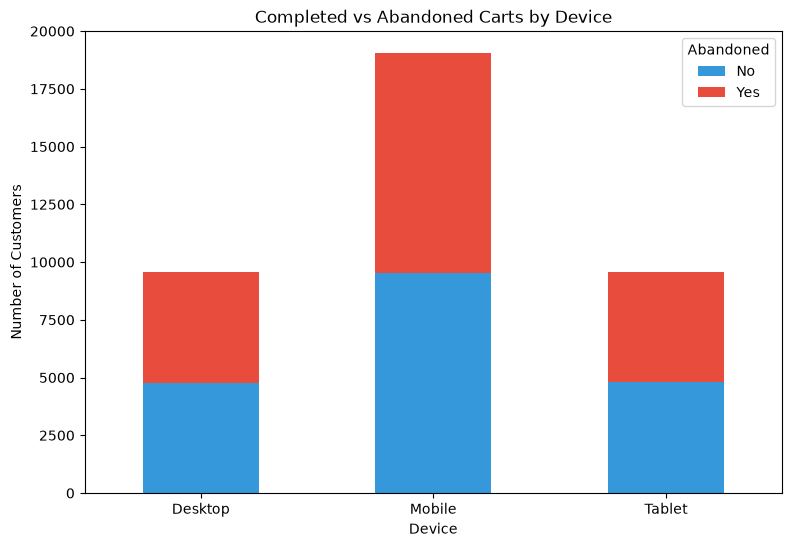

In [118]:
device_counts = pd.crosstab(
    df["device"],
    df["abandoned"]
)

device_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(9,6),
    color=["#3498DB", "#E74C3C"]
)

plt.title("Completed vs Abandoned Carts by Device")
plt.xlabel("Device")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Abandoned")
plt.show()

#### Histogram

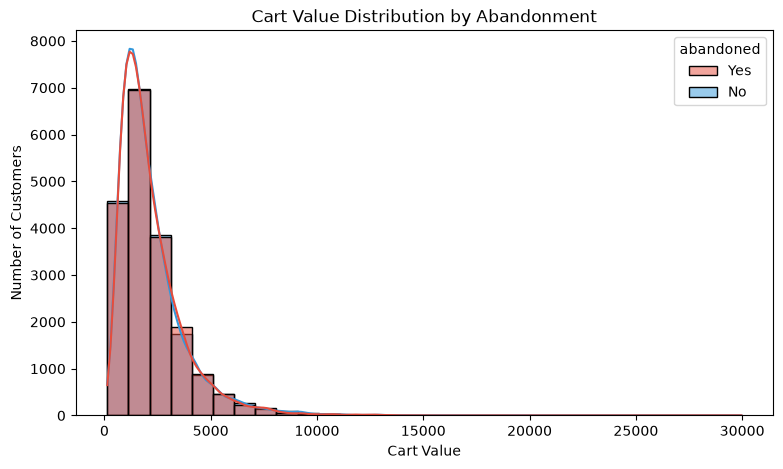

In [119]:
plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="cart_value",
    hue="abandoned",
    bins=30,
    kde=True,
    palette={
        "Yes": "#E74C3C",
        "No": "#3498DB"
    }
)

plt.title("Cart Value Distribution by Abandonment")
plt.xlabel("Cart Value")
plt.ylabel("Number of Customers")
plt.show()

#### Session Duration Distribution

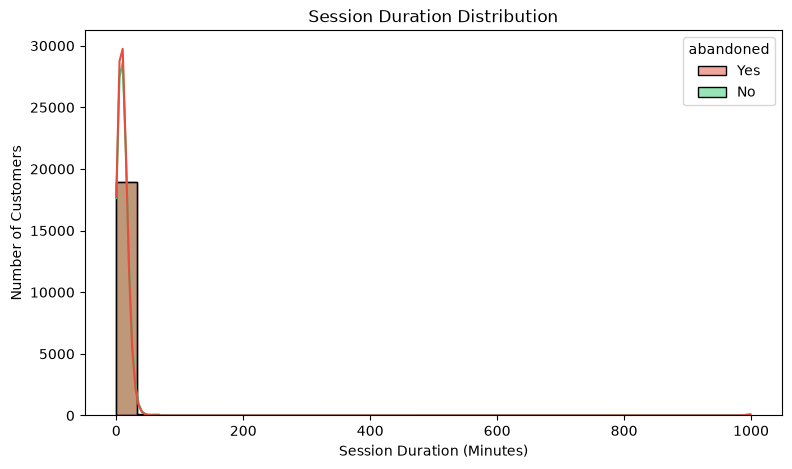

In [120]:
plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="session_duration_min",
    hue="abandoned",
    bins=30,
    kde=True,
    palette={
        "Yes": "#E74C3C",
        "No": "#2ECC71"
    }
)

plt.title("Session Duration Distribution")
plt.xlabel("Session Duration (Minutes)")
plt.ylabel("Number of Customers")
plt.show()

#### Create a Summary Table

In [121]:
summary = df.groupby("abandoned")[
    [
        "age",
        "cart_value",
        "discount_percent",
        "session_duration_min",
        "pages_viewed",
        "previous_purchases",
        "shipping_cost"
    ]
].mean()

summary

,age,cart_value,discount_percent,session_duration_min,pages_viewed,previous_purchases,shipping_cost
abandoned,,,,,,,
No,41.102116,2211.882829,14.44203,11.798291,12.575251,3.506127,105.771994
Yes,41.141225,2211.419951,14.651132,11.443495,12.410516,3.517194,106.209792


#### Find the Actual Abandonment Rate

In [127]:
def abandonment_rate(column):
    return (
        pd.crosstab(
            df[column],
            df["abandoned"],
            normalize="index"
        ) * 100
    )
    
    

In [128]:
abandonment_rate("device")

abandoned,No,Yes
device,,
Desktop,49.895288,50.104712
Mobile,49.973753,50.026247
Tablet,50.261178,49.738822


In [129]:
abandonment_rate("gender")

abandoned,No,Yes
gender,,
Female,50.223036,49.776964
Male,50.187376,49.812624
Other,49.414520,50.585480


In [130]:
abandonment_rate("payment_method")

abandoned,No,Yes
payment_method,,
Cod,49.628146,50.371854
Credit Card,50.349854,49.650146
Debit Card,50.511073,49.488927
Net Banking,49.368559,50.631441
Upi,50.348736,49.651264
Wallet,50.750496,49.249504


In [131]:
abandonment_rate("product_category")

abandoned,No,Yes
product_category,,
Beauty,50.318640,49.681360
Books,51.359047,48.640953
Electronics,49.320849,50.679151
Fashion,49.764521,50.235479
Home & Kitchen,50.111651,49.888349
Sports,50.399382,49.600618
